# Preprocessing Non-Linear — PCHIP

**Proyek Sains Data (PSD)**  
**Polutan:** CO, NO₂, SO₂  
**Wilayah:** Kecamatan Menganti, Kabupaten Gresik

Notebook ini dibuat sebagai **eksperimen pembanding** terhadap preprocessing linear yang sudah digunakan pada notebook analisis utama.

Alur:

```text
Data time series
      ↓
Pemeriksaan missing value
      ↓
Linear interpolation  ─────┐
                           ├── dibandingkan
PCHIP interpolation  ─────┘
      ↓
Forward fill / backward fill
      ↓
Simpan hasil PCHIP
```

> **Catatan:** file hasil preprocessing linear yang sudah ada tidak diubah. Hasil PCHIP disimpan pada folder terpisah.


In [1]:
# 1. Import library

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.interpolate import PchipInterpolator

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:.8g}")

print("Library siap digunakan.")


Library siap digunakan.


In [2]:
# 2. Konfigurasi path

BASE = Path("..")

PROCESSED_DIR = BASE / "data" / "processed"
PCHIP_DIR = PROCESSED_DIR / "nonlinear"

PCHIP_DIR.mkdir(parents=True, exist_ok=True)

RAW_FILES = {
    "NO2": PROCESSED_DIR / "menganti_NO2_daily.csv",
    "CO": PROCESSED_DIR / "menganti_CO_daily.csv",
    "SO2": PROCESSED_DIR / "menganti_SO2_daily.csv",
}

OUTPUT_FILES = {
    "NO2": PCHIP_DIR / "menganti_NO2_pchip.csv",
    "CO": PCHIP_DIR / "menganti_CO_pchip.csv",
    "SO2": PCHIP_DIR / "menganti_SO2_pchip.csv",
}

print("Input:")
for pol, path in RAW_FILES.items():
    print(f"{pol:>3} :", path)

print("\nOutput:")
for pol, path in OUTPUT_FILES.items():
    print(f"{pol:>3} :", path)


Input:
NO2 : ..\data\processed\menganti_NO2_daily.csv
 CO : ..\data\processed\menganti_CO_daily.csv
SO2 : ..\data\processed\menganti_SO2_daily.csv

Output:
NO2 : ..\data\processed\nonlinear\menganti_NO2_pchip.csv
 CO : ..\data\processed\nonlinear\menganti_CO_pchip.csv
SO2 : ..\data\processed\nonlinear\menganti_SO2_pchip.csv


## 3. Membaca data time series

Data yang digunakan adalah file time series harian Menganti yang sudah tersedia sebelum ekstraksi fitur.

Pada tahap ini kita **tidak mengubah file asli**.


In [3]:
# 3.1 Load data dan pemeriksaan awal

ts_data = {}

for pol, path in RAW_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"File {pol} tidak ditemukan: {path}")

    df = pd.read_csv(path, parse_dates=["date"])
    df = df.sort_values("date").reset_index(drop=True)

    # Pastikan nilai polutan numerik
    df[pol] = pd.to_numeric(df[pol], errors="coerce")

    ts_data[pol] = df

    print(
        f"{pol}: shape={df.shape}, "
        f"missing={df[pol].isna().sum()}, "
        f"tanggal={df['date'].min().date()} s.d. {df['date'].max().date()}"
    )


NO2: shape=(366, 2), missing=151, tanggal=2025-08-31 s.d. 2026-08-31
CO: shape=(366, 2), missing=110, tanggal=2025-08-31 s.d. 2026-08-31
SO2: shape=(366, 2), missing=110, tanggal=2025-08-31 s.d. 2026-08-31


In [4]:
# 3.2 Statistik missing value

missing_summary = pd.DataFrame([
    {
        "polutan": pol,
        "jumlah_data": len(df),
        "missing": int(df[pol].isna().sum()),
        "missing_%": float(df[pol].isna().mean() * 100),
        "valid": int(df[pol].notna().sum()),
    }
    for pol, df in ts_data.items()
])

display(missing_summary)


,polutan,jumlah_data,missing,missing_%,valid
0,NO2,366,151,41.256831,215
1,CO,366,110,30.054645,256
2,SO2,366,110,30.054645,256


# 4. Fungsi interpolasi

Dua metode dibandingkan:

## Linear interpolation

Menghubungkan dua titik yang diketahui dengan garis lurus.

## PCHIP

**Piecewise Cubic Hermite Interpolating Polynomial** menggunakan polinom kubik per segmen dengan bentuk yang mengikuti titik data. PCHIP digunakan di sini sebagai metode non-linear yang tetap menjaga bentuk data dan menghindari overshoot yang umum pada spline kubik biasa.

Setelah interpolasi pada bagian yang berada di dalam rentang data valid, nilai yang masih kosong pada ujung deret dilengkapi menggunakan `ffill()` dan `bfill()`.


In [5]:
# 4.1 Fungsi linear

def interpolate_linear(series):
    result = series.copy()

    result = result.interpolate(method="linear")
    result = result.ffill().bfill()

    return result


# 4.2 Fungsi PCHIP

def interpolate_pchip(series):
    result = series.copy()

    valid = result.dropna()

    if len(valid) < 2:
        raise ValueError("PCHIP membutuhkan minimal dua nilai valid.")

    x_valid = valid.index.to_numpy(dtype=float)
    y_valid = valid.to_numpy(dtype=float)

    interpolator = PchipInterpolator(
        x_valid,
        y_valid
    )

    x_all = np.arange(len(result), dtype=float)

    missing = result.isna()

    # PCHIP hanya digunakan di dalam rentang titik valid
    inside = (
        missing
        & (x_all >= x_valid.min())
        & (x_all <= x_valid.max())
    )

    result.loc[inside] = interpolator(x_all[inside])

    # Lengkapi bagian ujung jika masih ada NaN
    result = result.ffill().bfill()

    return result


In [6]:
# 5. Terapkan linear dan PCHIP

comparison_data = {}

for pol, df in ts_data.items():
    original = df[pol].copy()

    linear = interpolate_linear(original)
    pchip = interpolate_pchip(original)

    comparison = pd.DataFrame({
        "date": df["date"],
        "original": original,
        "linear": linear,
        "pchip": pchip
    })

    comparison_data[pol] = comparison

    print(f"\n=== {pol} ===")
    print("Missing asli :", comparison["original"].isna().sum())
    print("Missing linear:", comparison["linear"].isna().sum())
    print("Missing PCHIP :", comparison["pchip"].isna().sum())



=== NO2 ===
Missing asli : 151
Missing linear: 0
Missing PCHIP : 0

=== CO ===
Missing asli : 110
Missing linear: 0
Missing PCHIP : 0

=== SO2 ===
Missing asli : 110
Missing linear: 0
Missing PCHIP : 0


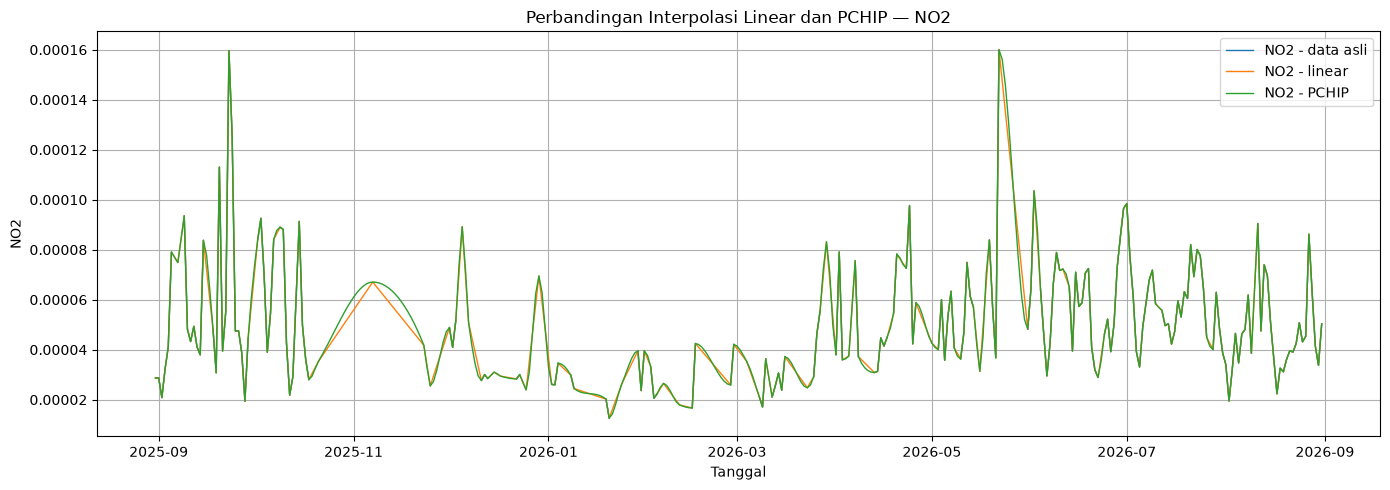

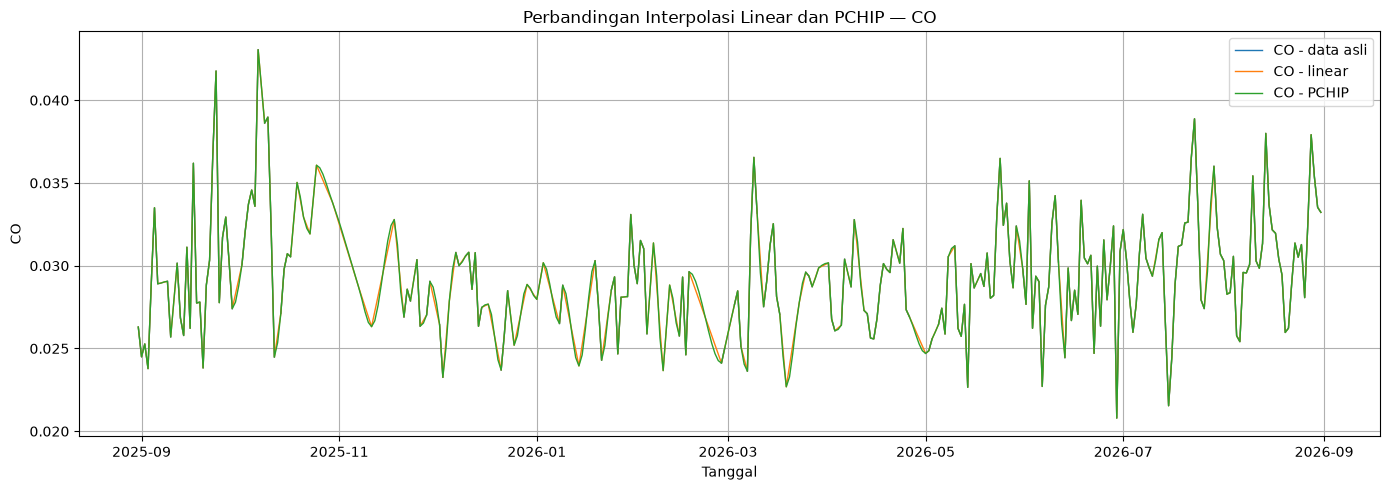

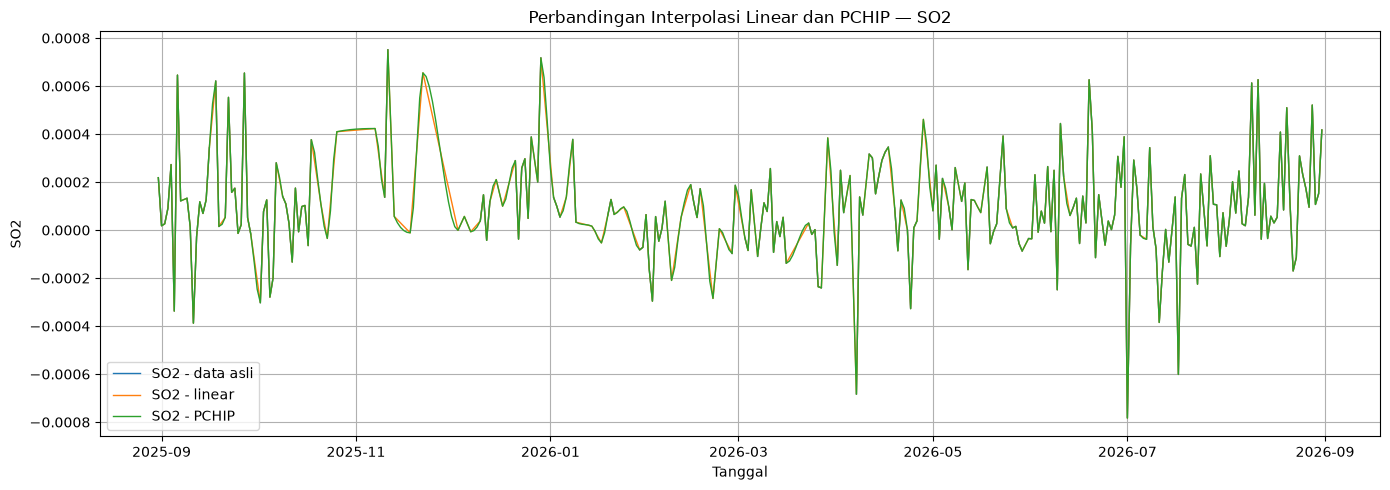

In [7]:
# 6. Visualisasi perbandingan

for pol, comparison in comparison_data.items():
    plt.figure(figsize=(14, 5))

    plt.plot(
        comparison["date"],
        comparison["original"],
        label=f"{pol} - data asli",
        linewidth=1
    )

    plt.plot(
        comparison["date"],
        comparison["linear"],
        label=f"{pol} - linear",
        linewidth=1
    )

    plt.plot(
        comparison["date"],
        comparison["pchip"],
        label=f"{pol} - PCHIP",
        linewidth=1
    )

    plt.title(f"Perbandingan Interpolasi Linear dan PCHIP — {pol}")
    plt.xlabel("Tanggal")
    plt.ylabel(pol)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# 7. Ringkasan perbandingan

Nilai yang sudah ada pada data asli tidak diubah oleh kedua metode. Perbedaan utama terdapat pada nilai yang sebelumnya missing.

Tabel berikut memeriksa apakah kedua hasil preprocessing sudah tidak memiliki missing value.


In [8]:
comparison_summary = []

for pol, comparison in comparison_data.items():
    original_mask = comparison["original"].notna()

    comparison_summary.append({
        "polutan": pol,
        "data": len(comparison),
        "missing_asli": int(comparison["original"].isna().sum()),
        "missing_linear": int(comparison["linear"].isna().sum()),
        "missing_pchip": int(comparison["pchip"].isna().sum()),
        "max_diff_linear_vs_original_valid": float(
            (comparison.loc[original_mask, "linear"]
             - comparison.loc[original_mask, "original"]).abs().max()
        ),
        "max_diff_pchip_vs_original_valid": float(
            (comparison.loc[original_mask, "pchip"]
             - comparison.loc[original_mask, "original"]).abs().max()
        ),
    })

comparison_summary = pd.DataFrame(comparison_summary)

display(comparison_summary)


,polutan,data,missing_asli,missing_linear,missing_pchip,max_diff_linear_vs_original_valid,max_diff_pchip_vs_original_valid
0,NO2,366,151,0,0,0,0
1,CO,366,110,0,0,0,0
2,SO2,366,110,0,0,0,0


# 8. Simpan hasil preprocessing PCHIP

File linear yang sudah digunakan pada analisis utama **tidak ditimpa**.

Hasil PCHIP disimpan pada:

```text
data/processed/nonlinear/
```

dengan nama:

- `menganti_NO2_pchip.csv`
- `menganti_CO_pchip.csv`
- `menganti_SO2_pchip.csv`


In [9]:
# 8.1 Simpan CSV PCHIP

for pol, comparison in comparison_data.items():
    output = comparison[["date", "pchip"]].copy()
    output = output.rename(columns={"pchip": pol})

    output.to_csv(
        OUTPUT_FILES[pol],
        index=False
    )

    print(f"{pol}: {OUTPUT_FILES[pol]}")


NO2: ..\data\processed\nonlinear\menganti_NO2_pchip.csv
CO: ..\data\processed\nonlinear\menganti_CO_pchip.csv
SO2: ..\data\processed\nonlinear\menganti_SO2_pchip.csv


In [10]:
# 8.2 Validasi file keluaran

for pol, path in OUTPUT_FILES.items():
    check = pd.read_csv(path, parse_dates=["date"])

    print(
        f"{pol}: shape={check.shape}, "
        f"missing={check[pol].isna().sum()}, "
        f"file_exists={path.exists()}"
    )


NO2: shape=(366, 2), missing=0, file_exists=True
CO: shape=(366, 2), missing=0, file_exists=True
SO2: shape=(366, 2), missing=0, file_exists=True


# 9. Langkah berikutnya

Setelah hasil PCHIP diperiksa, file ini dapat digunakan sebagai input untuk:

1. ekstraksi **68 fitur TSFEL** untuk NO₂, CO, dan SO₂;
2. penyimpanan fitur versi PCHIP secara terpisah dari fitur linear;
3. standardisasi;
4. PCA;
5. K-Means;
6. perbandingan Silhouette, Davies-Bouldin, dan Calinski-Harabasz antara preprocessing linear dan PCHIP.

**Jangan mengganti file preprocessing linear yang sudah ada.**
